# Day 6 · Demo 1: logistic regression

Bayesian statistics for PhD researchers, Aalborg University 2026. This notebook reproduces the figures of the **Day 6 morning slides**. Each section names its slide. Run it with the **R (bayes)** kernel from the `demos/` folder; the Stan model compiles the first time (about a minute).

The data are the slides' **illustrative** time-game data: one person, both Day 1 games, ten attempts at each of 5, 10 and 15 s without feedback and then with feedback. A **hit** is an attempt within 0.5 s of the target (`hit = 1`).

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # dplyr for summaries, ggplot2 for figures
library(cmdstanr)    # Stan from R
set.seed(2026)
options(width = 95, repr.plot.width = 8, repr.plot.height = 5, repr.plot.bg = "white")
theme_set(theme_minimal(base_size = 14) + theme(legend.position = "top"))
condition_colours <- c("without feedback" = "navy", "with feedback" = "tomato")

d <- read_csv("data/slides-one-person-hits.csv", show_col_types = FALSE) |>   # feedback, target_seconds, trial, hit
  mutate(x = target_seconds - 10,                                             # centred target
         condition = factor(if_else(feedback == 1, "with feedback", "without feedback"),
                            levels = c("without feedback", "with feedback")))   # order for tables and legends
head(d)

This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /tmp/claude-0/-home-claude/12b37052-eed4-57b8-ae0f-6457ef895351/scratchpad/env/bin/cmdstan



- CmdStan version: 2.40.0



feedback,target_seconds,trial,hit,x,condition
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
0,5,1,1,-5,without feedback
0,5,2,1,-5,without feedback
0,5,3,1,-5,without feedback
0,5,4,1,-5,without feedback
0,5,5,0,-5,without feedback
0,5,6,1,-5,without feedback


## 1. Hit or miss?

*Slide "Hit or miss?".* Hits out of 10 for each target and condition.

target_seconds,condition,hits,attempts,share
<dbl>,<fct>,<dbl>,<int>,<dbl>
5,without feedback,8,10,0.8
5,with feedback,9,10,0.9
10,without feedback,6,10,0.6
10,with feedback,8,10,0.8
15,without feedback,2,10,0.2
15,with feedback,3,10,0.3


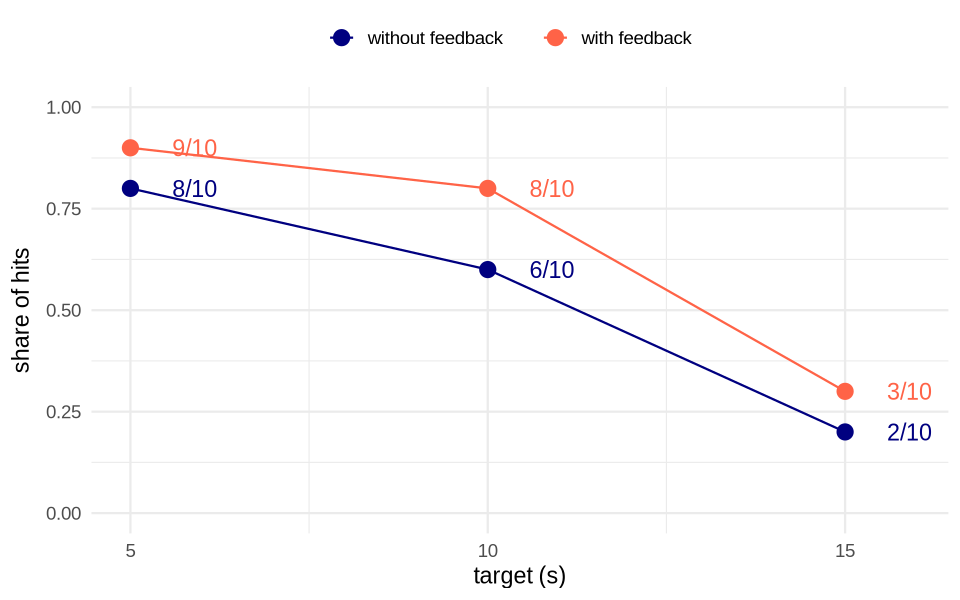

In [2]:
cells <- d |> group_by(target_seconds, condition) |>
  summarise(hits = sum(hit), attempts = n(), .groups = "drop") |>
  mutate(share = hits / attempts)
cells

ggplot(cells, aes(x = target_seconds, y = share, colour = condition)) +
  geom_line() + geom_point(size = 4) +
  geom_text(aes(label = paste0(hits, "/", attempts)), nudge_x = 0.9, show.legend = FALSE) +
  scale_colour_manual(values = condition_colours, name = NULL) +
  scale_x_continuous(breaks = c(5, 10, 15)) + coord_cartesian(ylim = c(0, 1)) +
  labs(x = "target (s)", y = "share of hits")

## 2. Why not a straight line for p?

*Slide "A yes/no outcome".* A straight line through her three shares without feedback, extended to targets of 0 and 25 s.

In [3]:
without <- cells |> filter(condition == "without feedback")
line <- lm(share ~ target_seconds, data = without)
coef(line)
predict(line, newdata = tibble(target_seconds = c(0, 25)))   # outside [0, 1]: impossible probabilities

(Intercept) target_seconds 
      1.133333      -0.060000

1          2 
 1.1333333 -0.3666667

## 3. Probability, odds and log-odds

*Slide "Probability, odds and log-odds".* `qlogis(p)` gives the log-odds, `plogis(eta)` turns log-odds back into a probability.

p,odds,log_odds,qlogis,back
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.10,0.1111111,-2.197225,-2.197225,0.10
0.25,0.3333333,-1.098612,-1.098612,0.25
0.50,1.0000000,0.000000,0.000000,0.50
0.75,3.0000000,1.098612,1.098612,0.75
0.90,9.0000000,2.197225,2.197225,0.90


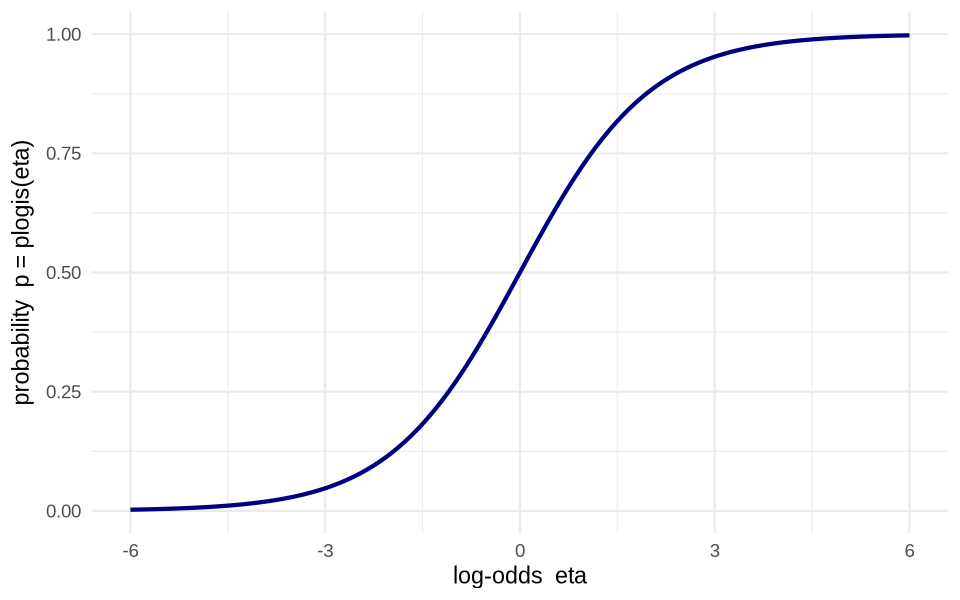

In [4]:
tibble(p = c(0.1, 0.25, 0.5, 0.75, 0.9)) |>
  mutate(odds = p / (1 - p), log_odds = log(odds), qlogis = qlogis(p), back = plogis(log_odds))

ggplot(tibble(eta = seq(-6, 6, by = 0.05)), aes(x = eta, y = plogis(eta))) +
  geom_line(colour = "navy", linewidth = 1.2) +
  labs(x = "log-odds  eta", y = "probability  p = plogis(eta)")

## 4. Logistic regression generates yes/no data

*Slides "Logistic regression generates yes/no data" and "A second predictor: feedback".* Simulate her 60 attempts from logit(p) = α + β₁ x + β₂ f with α = 0.3, β₁ = −0.25, β₂ = 1.0: compute the log-odds, turn them into a probability, draw 0 or 1.

target_seconds,condition,p,simulated_hits
<dbl>,<fct>,<dbl>,<int>
5,without feedback,0.8249137,9
5,with feedback,0.9275735,10
10,without feedback,0.5744425,8
10,with feedback,0.7858350,8
15,without feedback,0.2788848,0
15,with feedback,0.5124974,2


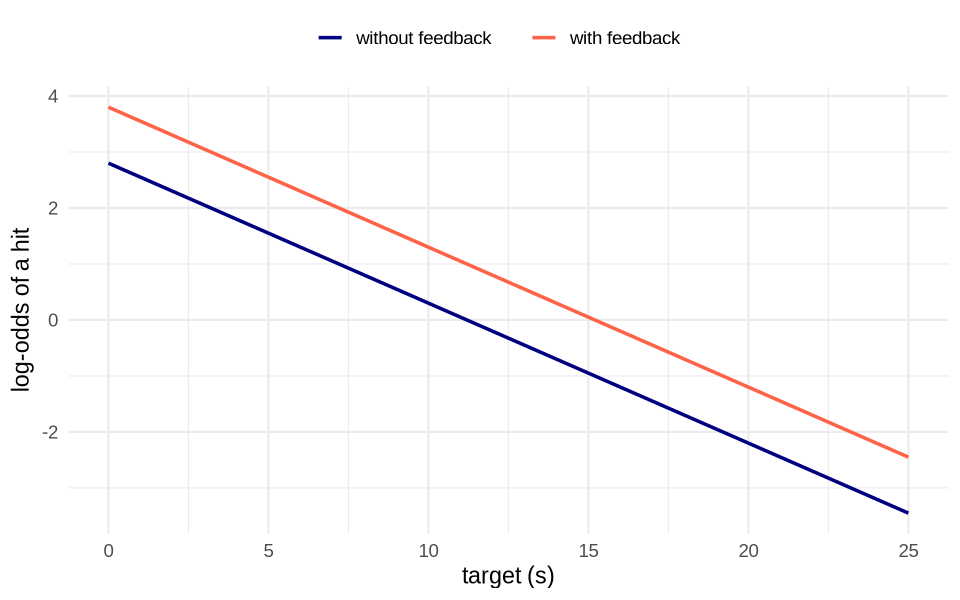

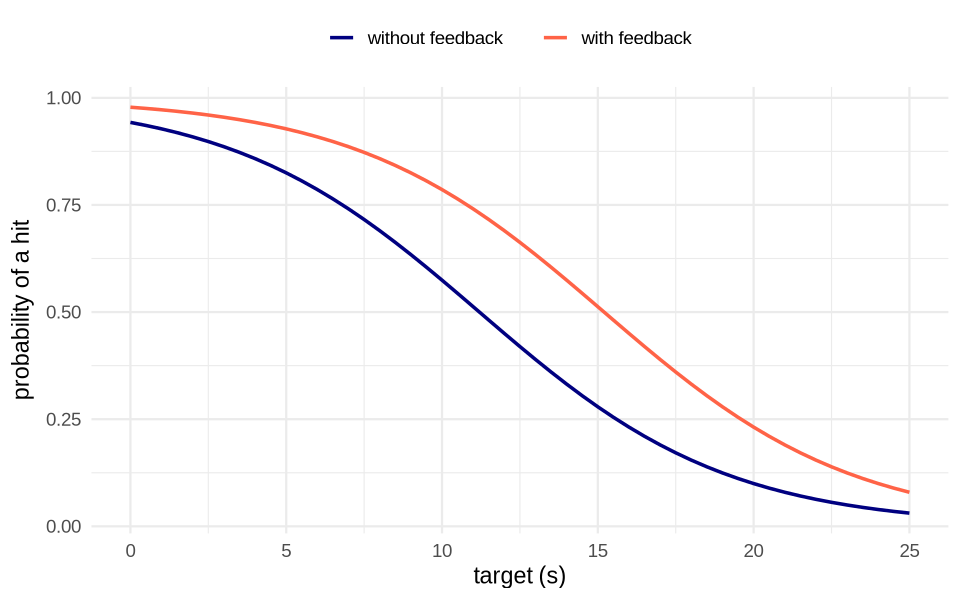

In [5]:
alpha <- 0.3; beta1 <- -0.25; beta2 <- 1.0
simulated <- d |>
  mutate(eta   = alpha + beta1 * x + beta2 * feedback,   # log-odds
         p     = plogis(eta),                            # probability
         y_sim = rbinom(n(), 1, p))                      # one yes/no draw each
simulated |> group_by(target_seconds, condition) |> summarise(p = first(p), simulated_hits = sum(y_sim), .groups = "drop")

curves <- expand_grid(feedback = c(0, 1), target = seq(0, 25, by = 0.5)) |>
  mutate(condition = factor(if_else(feedback == 1, "with feedback", "without feedback"), levels = c("without feedback", "with feedback")),
         eta = alpha + beta1 * (target - 10) + beta2 * feedback, p = plogis(eta))
ggplot(curves, aes(x = target, y = eta, colour = condition)) + geom_line(linewidth = 1) +
  scale_colour_manual(values = condition_colours, name = NULL) + labs(x = "target (s)", y = "log-odds of a hit")
ggplot(curves, aes(x = target, y = p, colour = condition)) + geom_line(linewidth = 1) +
  scale_colour_manual(values = condition_colours, name = NULL) + labs(x = "target (s)", y = "probability of a hit")

## 5. Odds ratios

*Slide "Reading the coefficients: odds ratios".*

In [6]:
c(odds_ratio_feedback = exp(beta2), odds_ratio_per_second = exp(beta1), odds_ratio_per_5_seconds = exp(5 * beta1),
  p_10s_without = plogis(alpha), p_10s_with = plogis(alpha + beta2))

odds_ratio_feedback    odds_ratio_per_second odds_ratio_per_5_seconds 
               2.7182818                0.7788008                0.2865048 
           p_10s_without               p_10s_with 
               0.5744425                0.7858350

## 6. Priors on the log-odds scale

*Slides "Priors on the log-odds scale" and "Prior predictive: curves of P(hit)".* Push prior draws of α through `plogis()` to see what they say about P(hit).

prior,share_extreme
<chr>,<dbl>
"alpha ~ Normal(0, 1.5)",0.00225
"alpha ~ Normal(0, 10)",0.64710


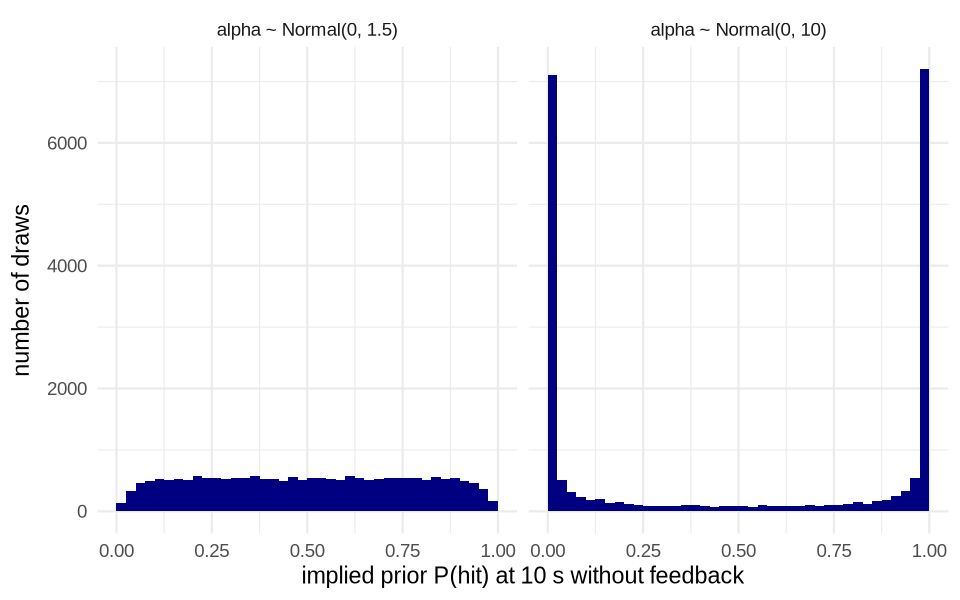

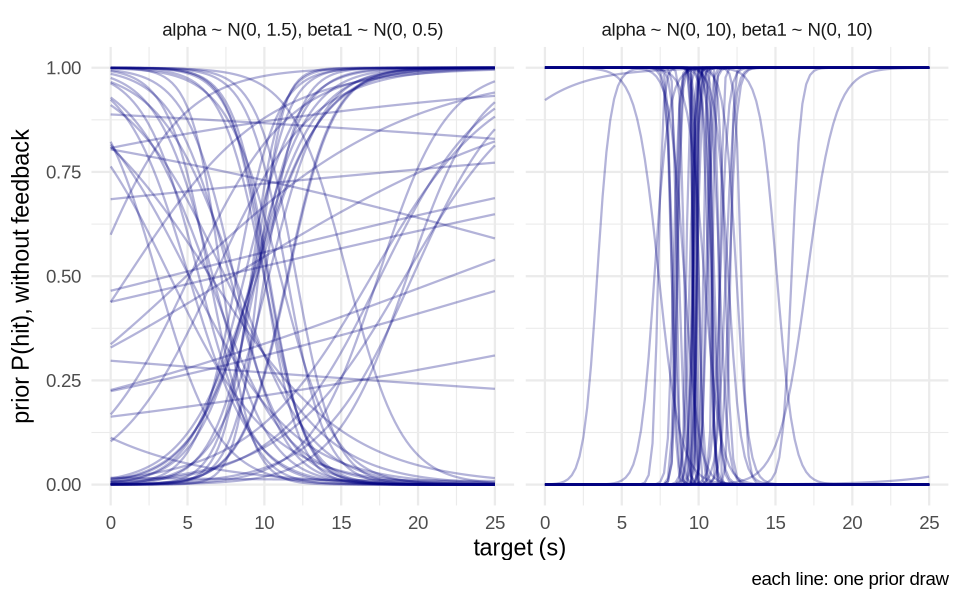

In [7]:
prior_p <- bind_rows(tibble(prior = "alpha ~ Normal(0, 1.5)", p = plogis(rnorm(20000, 0, 1.5))),
                     tibble(prior = "alpha ~ Normal(0, 10)",  p = plogis(rnorm(20000, 0, 10))))
prior_p |> group_by(prior) |> summarise(share_extreme = mean(p < 0.01 | p > 0.99))
ggplot(prior_p, aes(x = p)) + geom_histogram(breaks = seq(0, 1, by = 0.025), fill = "navy") + facet_wrap(~ prior) +
  labs(x = "implied prior P(hit) at 10 s without feedback", y = "number of draws")

prior_curves <- bind_rows(
    tibble(prior = "alpha ~ N(0, 1.5), beta1 ~ N(0, 0.5)", draw = 1:60, alpha = rnorm(60, 0, 1.5), beta1 = rnorm(60, 0, 0.5)),
    tibble(prior = "alpha ~ N(0, 10), beta1 ~ N(0, 10)",  draw = 1:60, alpha = rnorm(60, 0, 10),  beta1 = rnorm(60, 0, 10))) |>
  cross_join(tibble(target = seq(0, 25, by = 0.25))) |>
  mutate(p = plogis(alpha + beta1 * (target - 10)))
ggplot(prior_curves, aes(x = target, y = p, group = draw)) + geom_line(alpha = 0.3, colour = "navy") + facet_wrap(~ prior) +
  labs(x = "target (s)", y = "prior P(hit), without feedback", caption = "each line: one prior draw")

## 7. The design matrix and the Stan program

*Slides "The design matrix" and "The logistic model in Stan".* One row per attempt, one column per predictor. `X_new` holds the six cases we want predictions for.

In [8]:
X <- cbind(x = d$x, feedback = d$feedback)
X[c(1, 11, 31, 60), ]

cases <- expand_grid(feedback = c(0, 1), target_seconds = c(5, 10, 15))   # the six cases, in this order
X_new <- cbind(x = cases$target_seconds - 10, feedback = cases$feedback)
cases |> mutate(row = row_number())

writeLines(readLines("models/logistic.stan"))
stan_data <- list(N = nrow(d), K = ncol(X), X = X, y = d$hit, prior_sd = c(0.5, 1), M = nrow(X_new), X_new = X_new)

x,feedback
-5,0
0,0
-5,1
5,1


feedback,target_seconds,row
<dbl>,<dbl>,<int>
0,5,1
0,10,2
0,15,3
1,5,4
1,10,5
1,15,6


// Logistic regression with a design matrix
data {
  int<lower=1> N;                       // attempts
  int<lower=1> K;                       // predictors (columns of X)
  matrix[N, K] X;                       // design matrix
  array[N] int<lower=0, upper=1> y;     // 1 = hit, 0 = miss
  vector<lower=0>[K] prior_sd;          // prior SD of each coefficient (log-odds scale)
  int<lower=0> M;                       // cases to predict
  matrix[M, K] X_new;                   // their predictor values
}
parameters {
  real alpha;                           // log-odds of a hit when every predictor is 0
  vector[K] beta;                       // change in log-odds per unit of each predictor
}
model {
  alpha ~ normal(0, 1.5);
  beta ~ normal(0, prior_sd);
  y ~ bernoulli_logit(alpha + X * beta);
}
generated quantities {
  vector[M] p_new = inv_logit(alpha + X_new * beta);           // P(hit) for each case
  array[N] int y_rep = bernoulli_logit_rng(alpha + X * beta);  // a replicated datase

## 8. The fit

*Slide "The fit".* `beta[1]` belongs to the first column of X (the target), `beta[2]` to the second (feedback).

In [9]:
mod <- cmdstan_model("models/logistic.stan")
fit <- mod$sample(data = stan_data, chains = 4, seed = 2026, refresh = 0)
fit$summary(c("alpha", "beta"), "mean", ~quantile(.x, c(0.05, 0.95)), "rhat", "ess_bulk")
fit$diagnostic_summary()

draws <- fit$draws(format = "df") |> as_tibble()
tibble(quantity = c("odds ratio per second", "odds ratio for feedback"),
       q5  = c(quantile(exp(draws$`beta[1]`), 0.05), quantile(exp(draws$`beta[2]`), 0.05)),
       q95 = c(quantile(exp(draws$`beta[1]`), 0.95), quantile(exp(draws$`beta[2]`), 0.95)))
c(P_feedback_helps = mean(draws$`beta[2]` > 0))

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.1 seconds.
Chain 2 finished in 0.1 seconds.
Chain 3 finished in 0.1 seconds.
Chain 4 finished in 0.1 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.1 seconds.
Total execution time: 0.6 seconds.



variable,mean,5%,95%,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
alpha,0.2744005,-0.3738221,0.9360000,1.000539,2380.365
beta[1],-0.3121086,-0.4569706,-0.1798819,1.000823,2700.741
beta[2],0.5781720,-0.2825017,1.4565639,1.001691,2497.475


$num_divergent
[1] 0 0 0 0

$num_max_treedepth
[1] 0 0 0 0

$ebfmi
[1] 0.9765483 1.1461798 1.1236607 0.9856626

quantity,q5,q95
<chr>,<dbl>,<dbl>
odds ratio per second,0.6331989,0.8353688
odds ratio for feedback,0.7538954,4.2911908


P_feedback_helps 
         0.86025

The fitted curves: for each draw compute P(hit) on a grid of targets, then the mean and a 90% band.

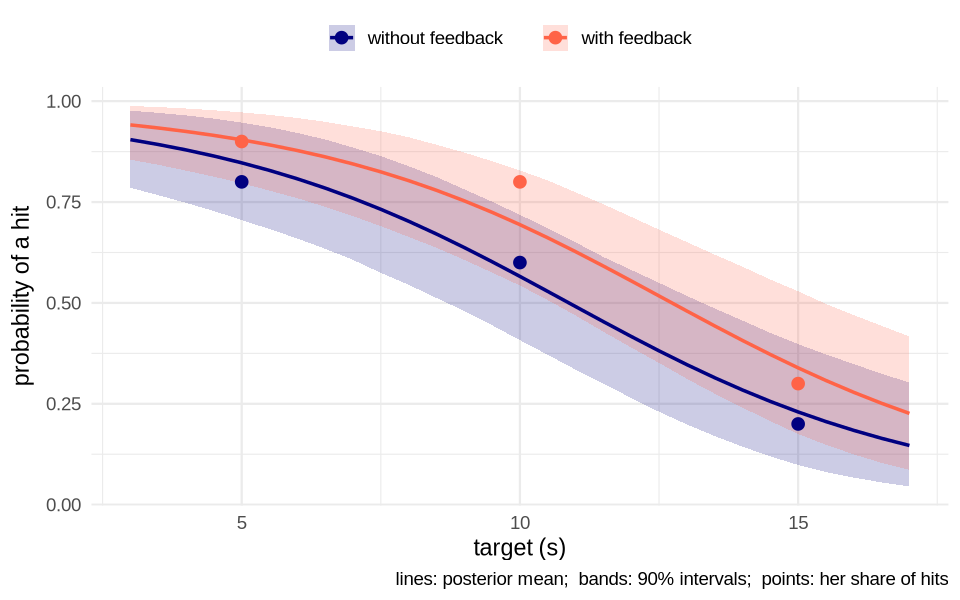

In [10]:
band <- draws |>
  select(.draw, alpha, b1 = `beta[1]`, b2 = `beta[2]`) |>
  cross_join(expand_grid(feedback = c(0, 1), target = seq(3, 17, by = 0.5))) |>
  mutate(p = plogis(alpha + b1 * (target - 10) + b2 * feedback),
         condition = factor(if_else(feedback == 1, "with feedback", "without feedback"),
                            levels = c("without feedback", "with feedback"))) |>
  group_by(condition, target) |>
  summarise(mean = mean(p), lo = quantile(p, 0.05), hi = quantile(p, 0.95), .groups = "drop")

ggplot(band, aes(x = target, colour = condition, fill = condition)) +
  geom_ribbon(aes(ymin = lo, ymax = hi), alpha = 0.2, colour = NA) +
  geom_line(aes(y = mean), linewidth = 1) +
  geom_point(data = cells, aes(x = target_seconds, y = share), size = 3) +
  scale_colour_manual(values = condition_colours, name = NULL) + scale_fill_manual(values = condition_colours, name = NULL) +
  labs(x = "target (s)", y = "probability of a hit", caption = "lines: posterior mean;  bands: 90% intervals;  points: her share of hits")

## 9. Predicted probabilities for chosen cases

*Slide "Predicted probabilities for chosen cases".* `p_new[k]` is P(hit) for row k of `X_new`. Her next 10 attempts at 15 s with feedback (case 6): for each draw, a binomial count with that draw's probability.

feedback,target_seconds,condition,mean,lo,hi
<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>
0,5,without feedback,0.8471289,0.70550758,0.9467453
0,10,without feedback,0.5656650,0.40761778,0.7182910
0,15,without feedback,0.2297358,0.09849792,0.3978061
1,5,with feedback,0.9041274,0.79666108,0.9722801
1,10,with feedback,0.6939089,0.54320600,0.8282654
1,15,with feedback,0.3389835,0.17512750,0.5288217


5%         95% P_5_or_more 
    1.00000     7.00000     0.26575

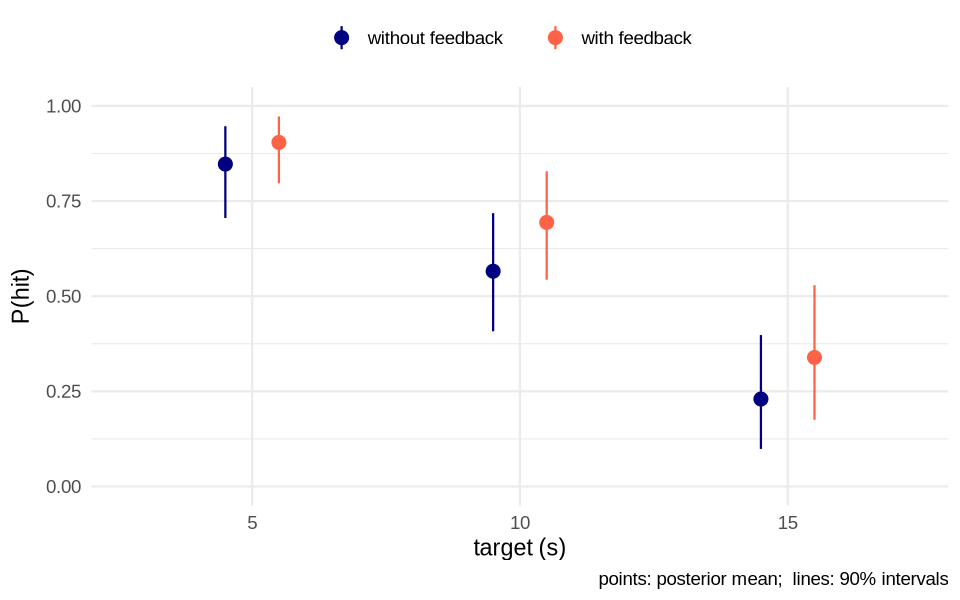

In [11]:
predictions <- cases |>
  mutate(condition = factor(if_else(feedback == 1, "with feedback", "without feedback"), levels = c("without feedback", "with feedback")),
         mean = fit$summary("p_new")$mean,
         lo   = fit$summary("p_new", ~quantile(.x, 0.05))[[2]],
         hi   = fit$summary("p_new", ~quantile(.x, 0.95))[[2]])
predictions

ggplot(predictions, aes(x = factor(target_seconds), y = mean, colour = condition)) +
  geom_pointrange(aes(ymin = lo, ymax = hi), position = position_dodge(width = 0.4)) +
  scale_colour_manual(values = condition_colours, name = NULL) + coord_cartesian(ylim = c(0, 1)) +
  labs(x = "target (s)", y = "P(hit)", caption = "points: posterior mean;  lines: 90% intervals")

y_next <- rbinom(nrow(draws), 10, draws$`p_new[6]`)
c(quantile(y_next, c(0.05, 0.95)), P_5_or_more = mean(y_next >= 5))

## 10. A predictive check for yes/no data

*Slide "A predictive check for yes/no data".* Replicate her 60 attempts once per draw and count the hits in each target and condition. This is what `y_rep` in the Stan program does; here we draw it in R so that each replicated attempt keeps its target and condition in the same row.

target_seconds,condition,lo,hi,hits
<dbl>,<fct>,<dbl>,<dbl>,<dbl>
5,without feedback,6,10,8
5,with feedback,7,10,9
10,without feedback,3,9,6
10,with feedback,4,9,8
15,without feedback,0,5,2
15,with feedback,1,7,3


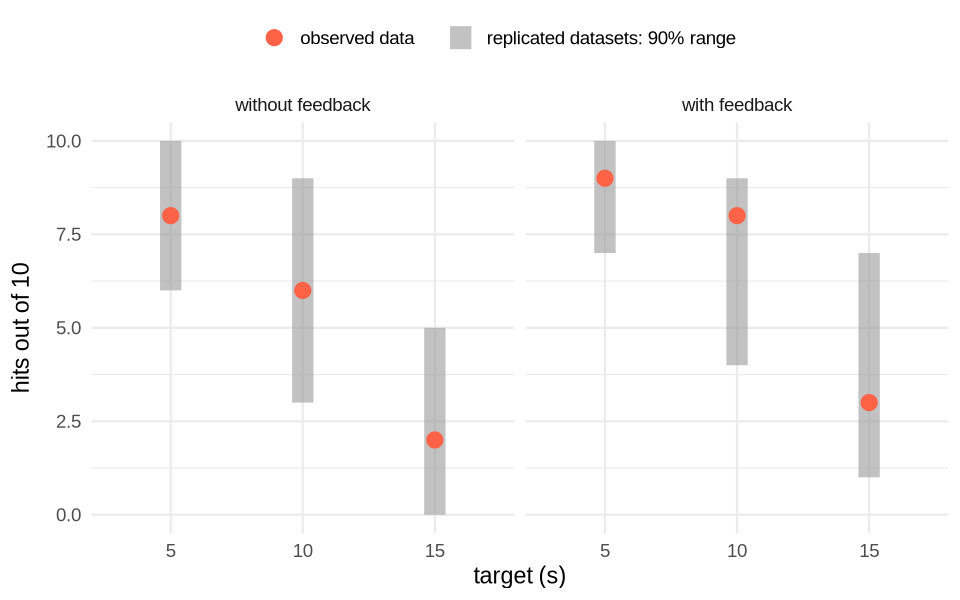

In [12]:
replicated <- draws |>
  select(.draw, alpha, b1 = `beta[1]`, b2 = `beta[2]`) |>
  cross_join(d |> select(target_seconds, condition, x, feedback)) |>
  mutate(y_rep = rbinom(n(), 1, plogis(alpha + b1 * x + b2 * feedback))) |>
  group_by(.draw, target_seconds, condition) |>
  summarise(rep_hits = sum(y_rep), .groups = "drop")

check <- replicated |> group_by(target_seconds, condition) |>
  summarise(lo = quantile(rep_hits, 0.05), hi = quantile(rep_hits, 0.95), .groups = "drop") |>
  left_join(cells |> select(target_seconds, condition, hits), by = c("target_seconds", "condition"))
check

ggplot(check, aes(x = factor(target_seconds))) +
  geom_linerange(aes(ymin = lo, ymax = hi, colour = "replicated datasets: 90% range"), linewidth = 6, alpha = 0.6) +
  geom_point(aes(y = hits, colour = "observed data"), size = 4) +
  facet_wrap(~ condition) +
  scale_colour_manual(values = c("replicated datasets: 90% range" = "grey60", "observed data" = "tomato"), name = NULL) +
  labs(x = "target (s)", y = "hits out of 10")